# Mapping Fertility Services in the United Kingdom
### DATASCI 530 - Project 2: Age differences, clinic variation, and geographic patterns

**Data source:** UK Human Fertilisation and Embryology Authority (HFEA) clinic directory and clinic profiles

**Research question:** How do publicly reported fertility treatment outcome rates vary across UK clinics by patient age, treatment type, and location?

**Website:** https://www.hfea.gov.uk/choose-a-fertility-clinic/search/

**Data collection date:** October 19-21, 2026 (I had to run the scraping process twice due to corrections)

Key findings:
1. Reported IVF birth rates are substantially higher for patients under 38 than for those aged 38 and over, among clinics with available figures.
2. Age gradients are also visible in the IUI and donor-insemination data, although these treatments report different outcome measures and should not be compared as equivalent percentages.
3. Clinic-level rates vary considerably, even within the same treatment and age category.
4. Published outcome statistics cover fewer than half of directory clinics; findings therefore describe the reporting subset, not all UK clinics.

## Background information
In Project 1, I collected information about fertility clinics in the United Kingdom by scraping the directory of the Human Fertilisation and Embryology Authority (HFEA) website. The final dataset includes 212 clinics, along with their addresses, geographic locations, and treatment outcome statistics if available. For clinics with statistics, I collected three outcome measures: IVF births per embryo transferred, IUI pregnancies per treatment, and donor insemination births per treatment. These measures are reported for three age groups (under 38, 38 and over, and all ages), alongside national comparison rates.

In this project, I use the dataset collected in Project 1 to examine variation in reported fertility treatment outcomes across clinics. I first describe the availability of outcome statistics and then compare reported rates across treatment types and age groups. I also examine how much rates vary between clinics, compare clinic rates with national rates, and explore geographic patterns using a map of fertility clinics in England.

Before I begin my analysis, I want to acknowledge that my analyses of treatment outcomes are restricted to clinics with available data and that not this information was not available for all clinics. I also account for the structure of the dataset, which contains multiple rows per clinic, to avoid giving greater weight to clinics with more observations.

## 1. Data Preparation
Before starting the analysis, I made a few decisions about how to work with the dataset in response to the feedback I received on Project 1. 

First, because the dataset is in long format, clinics with available outcome statistics appear multiple times, while clinics without outcome statistics appear only once. Using all rows to calculate clinic-level summaries would therefore give more weight to clinics with reported outcomes. To avoid this, I will create a separate dataset with one observation per clinic for analyses of clinic characteristics and data availability. For treatment outcome analyses, I will use one observation per clinic for each outcome and age group.

Second, I manually verified a random sample of 15 clinics with missing outcome information, including 10 clinics with no available outcome rates and five clinics with partially missing rates. I compared the missing information in my dataset with the statistics displayed on their HFEA profiles. I did not identify any scraping errors in the sample, as the missing values were consistent with the information available on the website. I therefore retained these values as missing in the dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the dataset collected in Project 1
data_path = Path("data/hfea_clinics_combined.csv")
df = pd.read_csv(data_path)

print(f"Rows: {len(df):,}")
print(f"Unique clinics: {df['clinic_name'].nunique():,}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 980
Unique clinics: 212
Columns: 21


,clinic_name,address,postcode,profile_url,directory_url,website,local_authority,local_authority_code,country,latitude,...,coordinate_source,current_location_verified,postcode_issue,outcome,age_group,clinic_rate,national_rate,period_start,period_end,reporting_year
0,Aberdeen Fertility Centre,"Department of Obstetrics & Gynaecology, Aberde...",AB25 2ZL,https://www.hfea.gov.uk/choose-a-fertility-cli...,https://www.hfea.gov.uk/choose-a-fertility-cli...,http://www.aberdeenfertility.org.uk/,Aberdeen City,S12000033,Scotland,57.155245,...,active_postcode,True,NaN,IVF births per embryo transferred,Under 38,36.0,35.0,2024-01-01,2024-12-31,2024.0
1,Aberdeen Fertility Centre,"Department of Obstetrics & Gynaecology, Aberde...",AB25 2ZL,https://www.hfea.gov.uk/choose-a-fertility-cli...,https://www.hfea.gov.uk/choose-a-fertility-cli...,http://www.aberdeenfertility.org.uk/,Aberdeen City,S12000033,Scotland,57.155245,...,active_postcode,True,NaN,IVF births per embryo transferred,38 and over,18.0,16.0,2024-01-01,2024-12-31,2024.0
2,Aberdeen Fertility Centre,"Department of Obstetrics & Gynaecology, Aberde...",AB25 2ZL,https://www.hfea.gov.uk/choose-a-fertility-cli...,https://www.hfea.gov.uk/choose-a-fertility-cli...,http://www.aberdeenfertility.org.uk/,Aberdeen City,S12000033,Scotland,57.155245,...,active_postcode,True,NaN,IVF births per embryo transferred,All,32.0,29.0,2024-01-01,2024-12-31,2024.0
3,Aberdeen Fertility Centre,"Department of Obstetrics & Gynaecology, Aberde...",AB25 2ZL,https://www.hfea.gov.uk/choose-a-fertility-cli...,https://www.hfea.gov.uk/choose-a-fertility-cli...,http://www.aberdeenfertility.org.uk/,Aberdeen City,S12000033,Scotland,57.155245,...,active_postcode,True,NaN,IUI pregnancies per treatment,Under 38,20.0,13.0,2025-01-01,2025-12-31,2025.0
4,Aberdeen Fertility Centre,"Department of Obstetrics & Gynaecology, Aberde...",AB25 2ZL,https://www.hfea.gov.uk/choose-a-fertility-cli...,https://www.hfea.gov.uk/choose-a-fertility-cli...,http://www.aberdeenfertility.org.uk/,Aberdeen City,S12000033,Scotland,57.155245,...,active_postcode,True,NaN,IUI pregnancies per treatment,38 and over,20.0,6.0,2025-01-01,2025-12-31,2025.0


In [3]:
# Missingness check

# Identify clinics with completely or partially missing outcome rates
missing_summary = (
    df.groupby("clinic_name")
    .agg(
        total_rates=("clinic_rate", "size"),
        available_rates=("clinic_rate", "count"),
        directory_url=("directory_url", "first"),
        profile_url=("profile_url", "first")
    )
    .reset_index()
)

# Clinics with no usable outcome rates
no_data = missing_summary[
    missing_summary["available_rates"] == 0
]

# Clinics with some rates available, but not all nine
partial_data = missing_summary[
    (missing_summary["available_rates"] > 0) &
    (missing_summary["available_rates"] < 9)
]

# Random sample, with a fixed seed for reproducibility
sample_no_data = no_data.sample(n=10, random_state=42)
sample_partial = partial_data.sample(n=5, random_state=42)

verification = pd.concat([
    sample_no_data.assign(sample_type="No outcome rates"),
    sample_partial.assign(sample_type="Partially missing rates")
])

verification = verification[
    ["clinic_name", "sample_type", "available_rates",
     "directory_url", "profile_url"]
].reset_index(drop=True)

verification


,clinic_name,sample_type,available_rates,directory_url,profile_url
0,Ipswich IVF,No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,None
1,Orian Gametes,No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,https://www.hfea.gov.uk/choose-a-fertility-cli...
2,Alma Fertility,No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,None
3,Fertility Plus,No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,None
4,CREATE Fertility Wolverhampton,No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,None
5,Worcestershire Fertility (consultations only -...,No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,None
6,Lister Fertility Clinic at The Shard,No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,None
7,"Ayrshire Fertility Unit, University Hospital C...",No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,https://www.hfea.gov.uk/choose-a-fertility-cli...
8,Oxford Reproductive Health (OxRH),No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,None
9,London Sperm Bank (LSB) London Bridge,No outcome rates,0,https://www.hfea.gov.uk/choose-a-fertility-cli...,https://www.hfea.gov.uk/choose-a-fertility-cli...


In [3]:
# Clinic-level dataset
clinics = df.drop_duplicates(subset=["clinic_name"]).copy()

# Identify clinics with at least one reported outcome rate
reporting = (
    df.groupby("clinic_name")["clinic_rate"]
    .apply(lambda x: x.notna().any())
    .rename("has_outcome_data")
)

clinics = clinics.drop(columns=["has_outcome_data"], errors="ignore")
clinics = clinics.merge(
    reporting,
    on="clinic_name",
    how="left"
)

print(f"Unique clinics: {len(clinics)}")
print("\nOutcome data availability:")
print(clinics["has_outcome_data"].value_counts())

# Check that each clinic appears only once
assert clinics["clinic_name"].is_unique


Unique clinics: 212

Outcome data availability:
has_outcome_data
False    118
True      94
Name: count, dtype: int64


In [4]:
# Outcome-level dataset

# Keep rows corresponding to a treatment outcome and age group
outcomes = df.dropna(subset=["outcome", "age_group"]).copy()

# Check that each clinic-outcome-age combination is unique
assert not outcomes.duplicated(
    subset=["clinic_name", "outcome", "age_group"]
).any()

print(f"Outcome records: {len(outcomes):,}")
print(f"Clinics with outcome records: {outcomes['clinic_name'].nunique()}")

# Check how many usable rates are available for each outcome and age group
availability = (
    outcomes.groupby(["outcome", "age_group"])
    .agg(
        clinics_with_records=("clinic_name", "nunique"),
        clinics_with_rates=("clinic_rate", "count")
    )
    .reset_index()
)

availability

Outcome records: 864
Clinics with outcome records: 96


,outcome,age_group,clinics_with_records,clinics_with_rates
0,Donor insemination births per treatment,38 and over,96,75
1,Donor insemination births per treatment,All,96,77
2,Donor insemination births per treatment,Under 38,96,72
3,IUI pregnancies per treatment,38 and over,96,51
4,IUI pregnancies per treatment,All,96,56
5,IUI pregnancies per treatment,Under 38,96,48
6,IVF births per embryo transferred,38 and over,96,88
7,IVF births per embryo transferred,All,96,89
8,IVF births per embryo transferred,Under 38,96,88


## 2. Descriptive Statistics and Data Availability

Before examining treatment outcomes, I first describe the clinics included in the dataset and the availability of outcome statistics. Although the dataset includes 212 clinics, not all clinics have published treatment outcome rates. The number of clinics included in each analysis therefore depends on the outcome measure and age group.


In [8]:

# Create one row per clinic
clinics = df.drop_duplicates(subset=["clinic_name"]).copy()

# Identify clinics with at least one reported outcome rate
reporting = (
    df.groupby("clinic_name")["clinic_rate"]
    .apply(lambda x: x.notna().any())
    .rename("has_outcome_data")
)

clinics = clinics.drop(columns=["has_outcome_data"], errors="ignore")
clinics = clinics.merge(reporting, on="clinic_name", how="left")

print("Unique clinics:", len(clinics))
print(clinics["has_outcome_data"].value_counts())

# Clinic-level summary
n_clinics = len(clinics)
n_reporting = int(clinics["has_outcome_data"].sum())
n_not_reporting = n_clinics - n_reporting

country_counts = (
    clinics["country"]
    .fillna("Unknown")
    .value_counts()
)

rows = [
    ["Total clinics", n_clinics],
    ["Clinics with at least one reported rate", n_reporting],
    ["Clinics without a reported rate", n_not_reporting],
    ["Geographic distribution", None]
]

for country, count in country_counts.items():
    rows.append([f"    {country}", int(count)])

table1 = pd.DataFrame(
    rows,
    columns=["Characteristic", "Number of clinics"]
)

table1_display = (
    table1.style
    .format({"Number of clinics": "{:.0f}"}, na_rep="")
    .hide(axis="index")
    .set_caption("Table 1. Overview of fertility clinics in the dataset")
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding-bottom", "12px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#EAF1F5"),
                ("text-align", "left"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "8px"),
                ("border-bottom", "1px solid #E5E7EB")
            ]
        }
    ])
    .apply(
        lambda row: [
            "font-weight: bold" if row["Characteristic"] in [
                "Total clinics", "Geographic distribution"
            ] else ""
        ] * len(row),
        axis=1
    )
)

display(table1_display)

Unique clinics: 212
has_outcome_data
False    118
True      94
Name: count, dtype: int64


Characteristic,Number of clinics
Total clinics,212
Clinics with at least one reported rate,94
Clinics without a reported rate,118
Geographic distribution,
England,183
Scotland,12
Wales,9
Northern Ireland,3
Channel Islands,3
Unknown,2


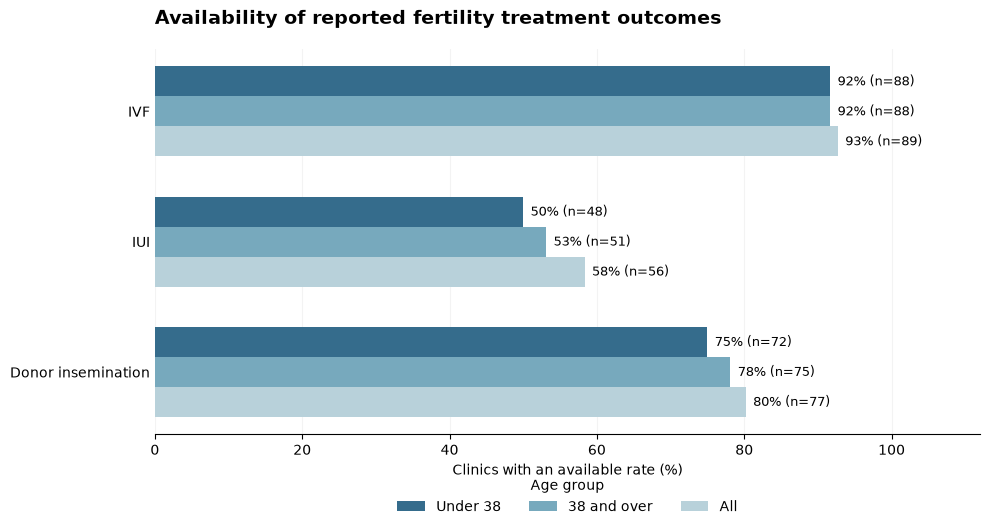

In [9]:
# Calculate reporting completeness by outcome and age group
reporting_fig = availability.copy()

reporting_fig["percentage"] = (
    reporting_fig["clinics_with_rates"] /
    reporting_fig["clinics_with_records"] * 100
)

treatment_labels = {
    "IVF births per embryo transferred": "IVF",
    "IUI pregnancies per treatment": "IUI",
    "Donor insemination births per treatment": "Donor insemination"
}

reporting_fig["treatment"] = (
    reporting_fig["outcome"].map(treatment_labels)
)

age_order = ["Under 38", "38 and over", "All"]
treatment_order = ["IVF", "IUI", "Donor insemination"]

fig, ax = plt.subplots(figsize=(10, 5.5))

colors = {
    "Under 38": "#356C8C",
    "38 and over": "#77A9BD",
    "All": "#B8D1DA"
}

y_positions = np.arange(len(treatment_order))
bar_height = 0.23

for i, age in enumerate(age_order):
    subset = (
        reporting_fig[reporting_fig["age_group"] == age]
        .set_index("treatment")
        .reindex(treatment_order)
    )

    positions = y_positions + (i - 1) * bar_height

    bars = ax.barh(
        positions,
        subset["percentage"],
        height=bar_height,
        color=colors[age],
        label=age
    )

    for bar, count in zip(bars, subset["clinics_with_rates"]):
        ax.text(
            bar.get_width() + 1,
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.0f}% (n={count})",
            va="center",
            fontsize=9
        )

ax.set_yticks(y_positions)
ax.set_yticklabels(treatment_order)
ax.invert_yaxis()

ax.set_xlim(0, 112)
ax.set_xlabel("Clinics with an available rate (%)")
ax.set_ylabel("")

ax.set_title(
    "Availability of reported fertility treatment outcomes",
    loc="left",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.legend(
    title="Age group",
    frameon=False,
    ncol=3,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.24)
)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

*Figure 1. Percentages are calculated among the 96 clinics with outcome records. The sample size labels indicate the number of clinics with a nonmissing rate for each treatment and age group.*

Of the 212 clinics in my dataset, 94 have at least one numerical treatment outcome rate available. Most clinics are located in England (183), followed by Scotland (12) and Wales (9).

Figure 1 shows that the availability of outcome statistics varies considerably by treatment type. IVF rates are available for 88–89 of the 96 clinics with outcome records, depending on age group. Donor insemination rates are available for 72–77 clinics, while IUI rates are available for only 48–56 clinics. This means that the number of clinics included in the following analyses will differ across treatments. In particular, comparisons involving IUI rates will be based on a smaller subset of clinics.

## 3. Differences in Fertility Treatment Outcomes by Age Group

I first examine how reported treatment outcomes differ across age groups. The HFEA reports rates for patients under 38, patients aged 38 and over, and all ages combined. For each treatment and age group, I calculate the mean, median, and standard deviation of clinic-level rates, along with the number of clinics with available data.

Each clinic contributes one observation to each treatment and age-group combination. These are unweighted averages of clinic-level rates. Since the three treatment measures use different denominators and IVF and donor insemination measure births while IUI measures pregnancies, I focus on differences between age groups within each treatment rather than directly comparing rates across treatments.

In [10]:

table2 = (
    outcomes.groupby(["outcome", "age_group"])
    .agg(
        n=("clinic_rate", "count"),
        mean=("clinic_rate", "mean"),
        median=("clinic_rate", "median"),
        sd=("clinic_rate", "std")
    )
    .reset_index()
)

short_names = {
    "IVF births per embryo transferred": "IVF",
    "IUI pregnancies per treatment": "IUI",
    "Donor insemination births per treatment": "Donor insemination"
}

table2["outcome"] = table2["outcome"].replace(short_names)

treatment_order = ["IVF", "IUI", "Donor insemination"]
age_order = ["Under 38", "38 and over", "All"]

table2["outcome"] = pd.Categorical(
    table2["outcome"],
    categories=treatment_order,
    ordered=True
)

table2["age_group"] = pd.Categorical(
    table2["age_group"],
    categories=age_order,
    ordered=True
)

table2 = table2.sort_values(["outcome", "age_group"])

table2 = table2.rename(columns={
    "outcome": "Treatment",
    "age_group": "Age group",
    "n": "Clinics (n)",
    "mean": "Mean (%)",
    "median": "Median (%)",
    "sd": "SD (pp)"
})

table2_display = (
    table2.style
    .format({
        "Mean (%)": "{:.1f}",
        "Median (%)": "{:.1f}",
        "SD (pp)": "{:.1f}"
    })
    .hide(axis="index")
    .set_caption(
        "Table 2. Descriptive statistics of reported treatment outcomes"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding-bottom", "12px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#EAF1F5"),
                ("text-align", "left"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "8px"),
                ("border-bottom", "1px solid #E5E7EB")
            ]
        }
    ])
)

display(table2_display)


Treatment,Age group,Clinics (n),Mean (%),Median (%),SD (pp)
IVF,Under 38,88,33.8,35.0,8.0
IVF,38 and over,88,16.2,16.0,6.0
IVF,All,89,28.2,28.0,7.1
IUI,Under 38,48,15.3,13.0,12.1
IUI,38 and over,51,9.5,7.0,11.0
IUI,All,56,12.4,10.5,10.2
Donor insemination,Under 38,72,17.6,16.5,9.1
Donor insemination,38 and over,75,9.4,7.0,9.4
Donor insemination,All,77,14.6,15.0,7.4


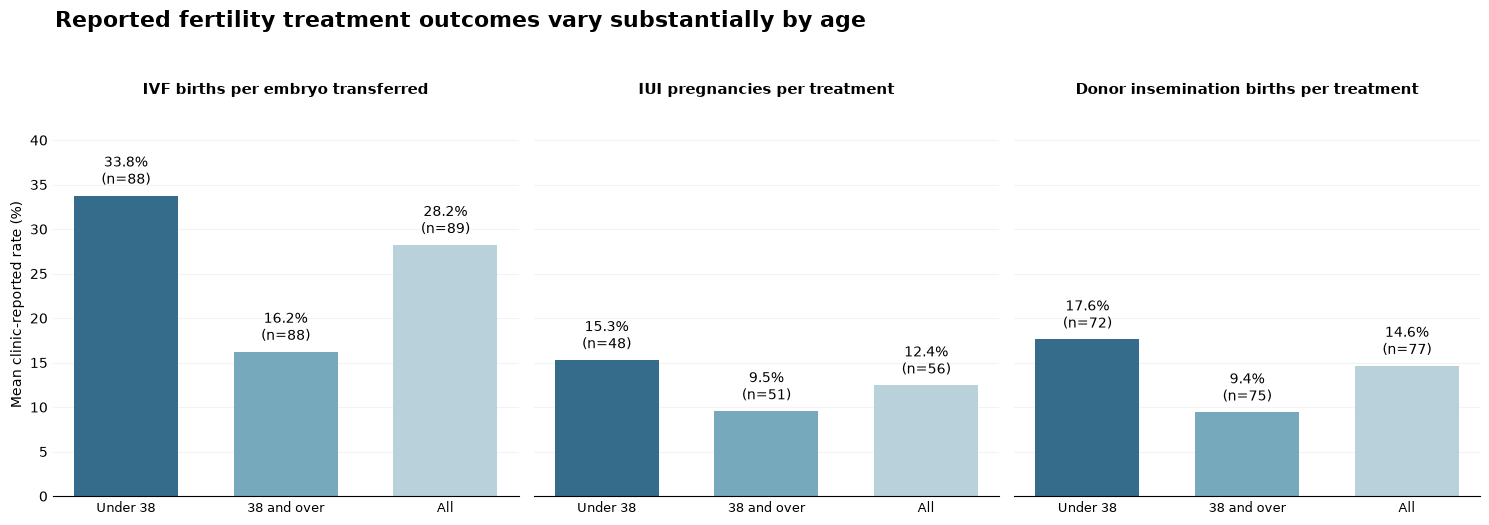

In [11]:

plot_data = outcomes.dropna(subset=["clinic_rate"]).copy()

treatment_names = {
    "IVF births per embryo transferred": "IVF births per embryo transferred",
    "IUI pregnancies per treatment": "IUI pregnancies per treatment",
    "Donor insemination births per treatment": "Donor insemination births per treatment"
}

age_groups = ["Under 38", "38 and over", "All"]

colors = {
    "Under 38": "#356C8C",
    "38 and over": "#77A9BD",
    "All": "#B8D1DA"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharey=True
)

for ax, (outcome_name, title) in zip(
    axes, treatment_names.items()
):
    subset = plot_data[
        plot_data["outcome"] == outcome_name
    ]

    summary = (
        subset.groupby("age_group")["clinic_rate"]
        .agg(["mean", "count"])
        .reindex(age_groups)
    )

    bars = ax.bar(
        age_groups,
        summary["mean"],
        color=[colors[age] for age in age_groups],
        width=0.65
    )

    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.8,
            f'{row["mean"]:.1f}%\n(n={int(row["count"])})',
            ha="center",
            va="bottom",
            fontsize=10
        )

    ax.set_title(title, fontsize=11, fontweight="bold", pad=14)
    ax.set_ylim(0, 43)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", length=0, labelsize=9)
    ax.tick_params(axis="y", length=0)

axes[0].set_ylabel("Mean clinic-reported rate (%)")

fig.suptitle(
    "Reported fertility treatment outcomes vary substantially by age",
    fontsize=16,
    fontweight="bold",
    x=0.04,
    ha="left",
    y=1.04
)

plt.tight_layout()
plt.show()

*Figure 2. Mean clinic-reported treatment outcome rates by age group. Bars represent unweighted averages across clinics with available rates, and labels indicate the number of clinics included. IVF and donor insemination outcomes measure births, while IUI outcomes measure pregnancies. Rates are therefore interpreted separately for each treatment.*

Table 2 and Figure 2 show that reported treatment outcomes are consistently higher for patients under 38 than for patients aged 38 and over. The largest difference is observed for IVF, where the average clinic-reported birth rate per embryo transferred is 33.77% for patients under 38, compared with 16.23% for patients aged 38 and over. This corresponds to a difference of approximately 17.5 percentage points.

A similar pattern is observed for the other two treatments. For donor insemination, the average birth rate per treatment is 17.61% for patients under 38 and 9.41% for patients aged 38 and over. For IUI, the corresponding pregnancy rates are 15.29% and 9.55%.

The standard deviations also indicate considerable variation between clinics, particularly for IUI. However, these differences should be interpreted cautiously because the reported rates are not adjusted for differences in patient characteristics or clinic treatment volumes.

## 4. Variation in Treatment Outcomes Across Clinics

In this section, I examine the distribution of clinic-level outcomes to see whether clinics report similar rates or whether there are big differences.

I focus on patients under 38 and patients aged 38 and over, excluding the all-ages category to avoid presenting overlapping age groups. I use boxplots to compare the distributions of reported rates within each treatment and age group.

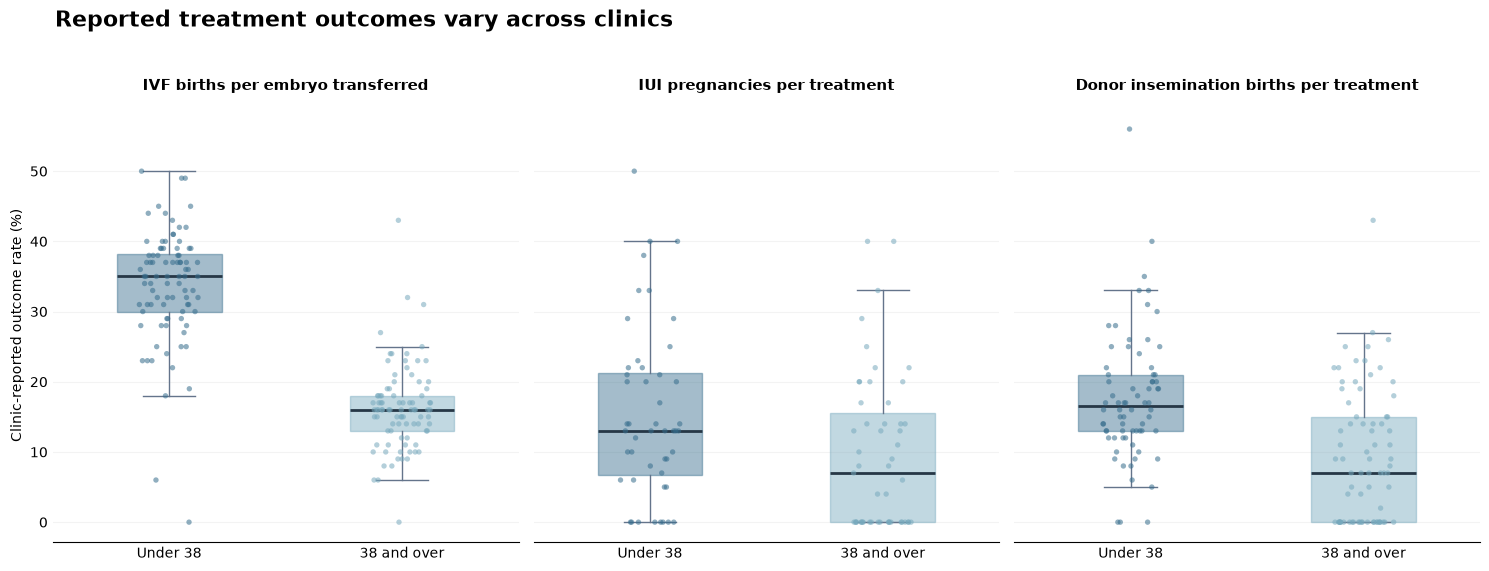

In [12]:
# Keep the two non-overlapping age groups
variation_data = outcomes[
    outcomes["age_group"].isin(["Under 38", "38 and over"])
].dropna(subset=["clinic_rate"]).copy()

treatments = {
    "IVF births per embryo transferred": "IVF births per embryo transferred",
    "IUI pregnancies per treatment": "IUI pregnancies per treatment",
    "Donor insemination births per treatment": "Donor insemination births per treatment"
}

age_groups = ["Under 38", "38 and over"]
colors = ["#356C8C", "#77A9BD"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5.5),
    sharey=True
)

rng = np.random.default_rng(42)

for ax, (outcome_name, title) in zip(axes, treatments.items()):

    subset = variation_data[
        variation_data["outcome"] == outcome_name
    ]

    groups = [
        subset.loc[
            subset["age_group"] == age, "clinic_rate"
        ].to_numpy()
        for age in age_groups
    ]

    box = ax.boxplot(
        groups,
        positions=[1, 2],
        widths=0.45,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "#263746", "linewidth": 2},
        whiskerprops={"color": "#64748B"},
        capprops={"color": "#64748B"}
    )

    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.45)
        patch.set_edgecolor(color)

    # Show individual clinic observations
    for i, (values, color) in enumerate(zip(groups, colors), start=1):
        jitter = rng.uniform(-0.13, 0.13, len(values))

        ax.scatter(
            np.full(len(values), i) + jitter,
            values,
            s=15,
            color=color,
            alpha=0.55,
            edgecolors="none",
            zorder=3
        )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(age_groups)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=14)

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=0)

axes[0].set_ylabel("Clinic-reported outcome rate (%)")

fig.suptitle(
    "Reported treatment outcomes vary across clinics",
    fontsize=16,
    fontweight="bold",
    x=0.04,
    ha="left",
    y=1.03
)

plt.tight_layout()
plt.show()


*Figure 3. Distribution of clinic-reported fertility treatment outcomes by age group. Each dot represents one clinic with an available rate. Boxes indicate the interquartile range (25th–75th percentiles), and horizontal lines indicate medians. IVF and donor insemination rates measure births, while IUI rates measure pregnancies. Clinic rates are not adjusted for differences in patient characteristics or treatment volumes.*

In [13]:

from IPython.display import display

# Keep the two non-overlapping age groups
variation_data = outcomes[
    outcomes["age_group"].isin(["Under 38", "38 and over"])
].dropna(subset=["clinic_rate"]).copy()

# Calculate distribution statistics
table3 = (
    variation_data
    .groupby(["outcome", "age_group"])["clinic_rate"]
    .agg(
        n="count",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

table3["IQR"] = table3["q3"] - table3["q1"]

# Shorten treatment names
treatment_labels = {
    "IVF births per embryo transferred": "IVF",
    "IUI pregnancies per treatment": "IUI",
    "Donor insemination births per treatment": "Donor insemination"
}

table3["outcome"] = table3["outcome"].replace(treatment_labels)

# Arrange rows
table3["outcome"] = pd.Categorical(
    table3["outcome"],
    categories=["IVF", "IUI", "Donor insemination"],
    ordered=True
)

table3["age_group"] = pd.Categorical(
    table3["age_group"],
    categories=["Under 38", "38 and over"],
    ordered=True
)

table3 = table3.sort_values(["outcome", "age_group"])

# Rename columns
table3 = table3.rename(columns={
    "outcome": "Treatment",
    "age_group": "Age group",
    "n": "Clinics (n)",
    "median": "Median (%)",
    "q1": "25th percentile (%)",
    "q3": "75th percentile (%)",
    "IQR": "IQR (pp)"
})

# Format and display
display(
    table3.style
    .format({
        "Median (%)": "{:.1f}",
        "25th percentile (%)": "{:.1f}",
        "75th percentile (%)": "{:.1f}",
        "IQR (pp)": "{:.1f}"
    })
    .hide(axis="index")
    .set_caption(
        "Table 3. Variation in reported treatment outcomes across clinics"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding-bottom", "12px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#EAF1F5"),
                ("text-align", "left"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "8px"),
                ("border-bottom", "1px solid #E5E7EB")
            ]
        }
    ])
)


Treatment,Age group,Clinics (n),Median (%),25th percentile (%),75th percentile (%),IQR (pp)
IVF,Under 38,88,35.0,30.0,38.2,8.2
IVF,38 and over,88,16.0,13.0,18.0,5.0
IUI,Under 38,48,13.0,6.8,21.2,14.5
IUI,38 and over,51,7.0,0.0,15.5,15.5
Donor insemination,Under 38,72,16.5,13.0,21.0,8.0
Donor insemination,38 and over,75,7.0,0.0,15.0,15.0


Figure 3 shows that treatment outcomes vary across clinics, but the variation is not the same for all treatments. IVF rates are more concentrated, especially for patients aged 38 and over, while IUI and donor insemination rates are more spread out. For example, the middle 50% of IVF rates for patients aged 38 and over fall between 13% and 18%, compared to 0% and 15.5% for IUI.

We also see the age differences from the previous section. For all three treatments, median rates are higher for patients under 38. Another interesting finding is that several clinics report zero rates, particularly for IUI and donor insemination among older patients. However, we should be careful when interpreting these differences since we do not have information about the number of treatments performed at each clinic.

## 5. Comparing Clinic Outcomes with National Rates

Next, I compare the reported clinic rates with the national rates provided by HFEA. For each clinic, I calculate the difference between its reported rate and the corresponding national rate for the same treatment, age group, and reporting period. A positive difference means that the clinic's reported rate is above the national figure, while a negative difference means that it is below. For this comparison, I focus on the two age groups separately rather than including the all-ages category.

In [14]:

# Keep records with both clinic and national rates
benchmark_data = outcomes[
    outcomes["age_group"].isin(["Under 38", "38 and over"])
].dropna(subset=["clinic_rate", "national_rate"]).copy()

# Difference in percentage points
benchmark_data["difference"] = (
    benchmark_data["clinic_rate"] - benchmark_data["national_rate"]
)

# Summarize the differences
benchmark_summary = (
    benchmark_data.groupby(["outcome", "age_group"])
    .agg(
        n=("difference", "count"),
        mean_difference=("difference", "mean"),
        median_difference=("difference", "median"),
        above_national=("difference", lambda x: (x > 0).sum()),
        below_national=("difference", lambda x: (x < 0).sum()),
        equal_national=("difference", lambda x: (x == 0).sum())
    )
    .reset_index()
)

benchmark_summary["pct_above"] = (
    benchmark_summary["above_national"] /
    benchmark_summary["n"] * 100
)

benchmark_summary["pct_below"] = (
    benchmark_summary["below_national"] /
    benchmark_summary["n"] * 100
)

# Create a presentation table
table4 = benchmark_summary.copy()

# Shorten treatment names
table4["outcome"] = table4["outcome"].replace({
    "IVF births per embryo transferred": "IVF",
    "IUI pregnancies per treatment": "IUI",
    "Donor insemination births per treatment": "Donor insemination"
})

# Order rows
table4["outcome"] = pd.Categorical(
    table4["outcome"],
    categories=["IVF", "IUI", "Donor insemination"],
    ordered=True
)

table4["age_group"] = pd.Categorical(
    table4["age_group"],
    categories=["Under 38", "38 and over"],
    ordered=True
)

table4 = table4.sort_values(["outcome", "age_group"])

# Select and rename columns
table4 = table4[
    ["outcome", "age_group", "n", "mean_difference",
     "median_difference", "pct_above", "pct_below"]
].rename(columns={
    "outcome": "Treatment",
    "age_group": "Age group",
    "n": "Clinics (n)",
    "mean_difference": "Mean difference (pp)",
    "median_difference": "Median difference (pp)",
    "pct_above": "Above national (%)",
    "pct_below": "Below national (%)"
})

# Format and display
display(
    table4.style
    .format({
        "Mean difference (pp)": "{:+.1f}",
        "Median difference (pp)": "{:+.1f}",
        "Above national (%)": "{:.1f}%",
        "Below national (%)": "{:.1f}%"
    })
    .hide(axis="index")
    .set_caption(
        "Table 4. Comparison of clinic-reported outcomes with national rates"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding-bottom", "12px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#EAF1F5"),
                ("text-align", "left"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "8px"),
                ("border-bottom", "1px solid #E5E7EB")
            ]
        }
    ])
)


Treatment,Age group,Clinics (n),Mean difference (pp),Median difference (pp),Above national (%),Below national (%)
IVF,Under 38,88,-1.2,+0.0,45.5%,46.6%
IVF,38 and over,88,+0.2,+0.0,42.0%,43.2%
IUI,Under 38,48,+2.3,+0.0,45.8%,41.7%
IUI,38 and over,51,+3.5,+1.0,51.0%,47.1%
Donor insemination,Under 38,72,+1.6,+0.5,50.0%,44.4%
Donor insemination,38 and over,75,+2.4,+0.0,49.3%,42.7%


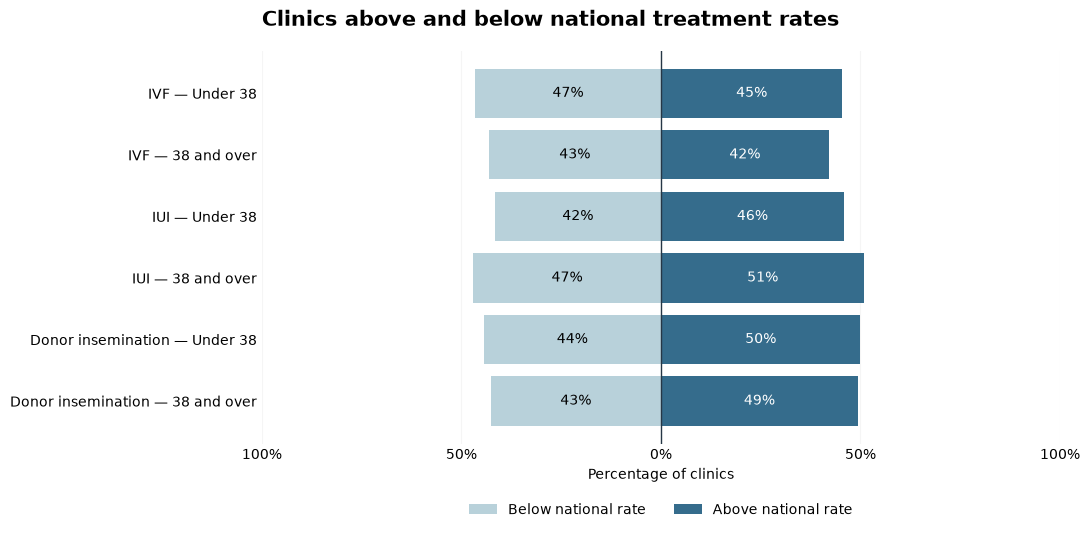

In [15]:

# Prepare data for plotting
plot_benchmark = benchmark_summary.copy()

short_names = {
    "IVF births per embryo transferred": "IVF",
    "IUI pregnancies per treatment": "IUI",
    "Donor insemination births per treatment": "Donor insemination"
}

plot_benchmark["treatment"] = plot_benchmark["outcome"].map(short_names)

plot_benchmark["label"] = (
    plot_benchmark["treatment"] + " — " +
    plot_benchmark["age_group"]
)

order = [
    f"{t} — {a}"
    for t in ["IVF", "IUI", "Donor insemination"]
    for a in ["Under 38", "38 and over"]
]

plot_benchmark = (
    plot_benchmark.set_index("label")
    .loc[order]
    .reset_index()
)

plot_benchmark["pct_below"] = (
    plot_benchmark["below_national"] / plot_benchmark["n"] * 100
)

plot_benchmark["pct_above"] = (
    plot_benchmark["above_national"] / plot_benchmark["n"] * 100
)

fig, ax = plt.subplots(figsize=(11, 5.5))

y = np.arange(len(plot_benchmark))

ax.barh(
    y,
    -plot_benchmark["pct_below"],
    color="#B8D1DA",
    label="Below national rate"
)

ax.barh(
    y,
    plot_benchmark["pct_above"],
    color="#356C8C",
    label="Above national rate"
)

for i, row in plot_benchmark.iterrows():
    if row["pct_below"] > 0:
        ax.text(
            -row["pct_below"] / 2, i,
            f'{row["pct_below"]:.0f}%',
            ha="center", va="center", fontsize=10
        )

    if row["pct_above"] > 0:
        ax.text(
            row["pct_above"] / 2, i,
            f'{row["pct_above"]:.0f}%',
            ha="center", va="center",
            fontsize=10, color="white"
        )

ax.set_yticks(y)
ax.set_yticklabels(plot_benchmark["label"])
ax.invert_yaxis()

ax.axvline(0, color="#263746", linewidth=1)
ax.set_xlim(-100, 100)

ax.set_xticks([-100, -50, 0, 50, 100])
ax.set_xticklabels(["100%", "50%", "0%", "50%", "100%"])

ax.set_xlabel("Percentage of clinics")
ax.set_title(
    "Clinics above and below national treatment rates",
    loc="left", fontsize=15, fontweight="bold", pad=18
)

ax.legend(
    frameon=False, ncol=2,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.22)
)

ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.tick_params(axis="both", length=0)
ax.grid(axis="x", alpha=0.12)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


*Figure 4. Percentage of clinics reporting rates above or below the corresponding HFEA national rates. Comparisons are made separately by treatment, age group, and reporting period. Clinics with rates exactly equal to the national rate are not included in either bar, so the two percentages may not add up to 100%.*

Figure 4 shows that clinics are fairly evenly split between reporting rates above and below the national averages. For IVF, slightly more clinics report rates below the national figures in both age groups. The opposite is true for IUI and donor insemination, where slightly more clinics report rates above the national figures. However, none of these differences are particularly large. Overall, there does not seem to be a strong tendency for clinics in the dataset to report rates either above or below the national averages.

## 6. Geographic Distribution of Fertility Clinics in England
Finally, I use the geographic coordinates collected in Project 1 to map fertility clinics in England. I focus on England because most of the clinics in the dataset are located there. The map shows the locations of clinics and their reported IVF birth rates per embryo transferred for patients under 38. Clinics without an available rate are shown in gray. This allows me to examine whether there are any visible geographic patterns in reported IVF outcomes, while also showing where outcome information is missing.

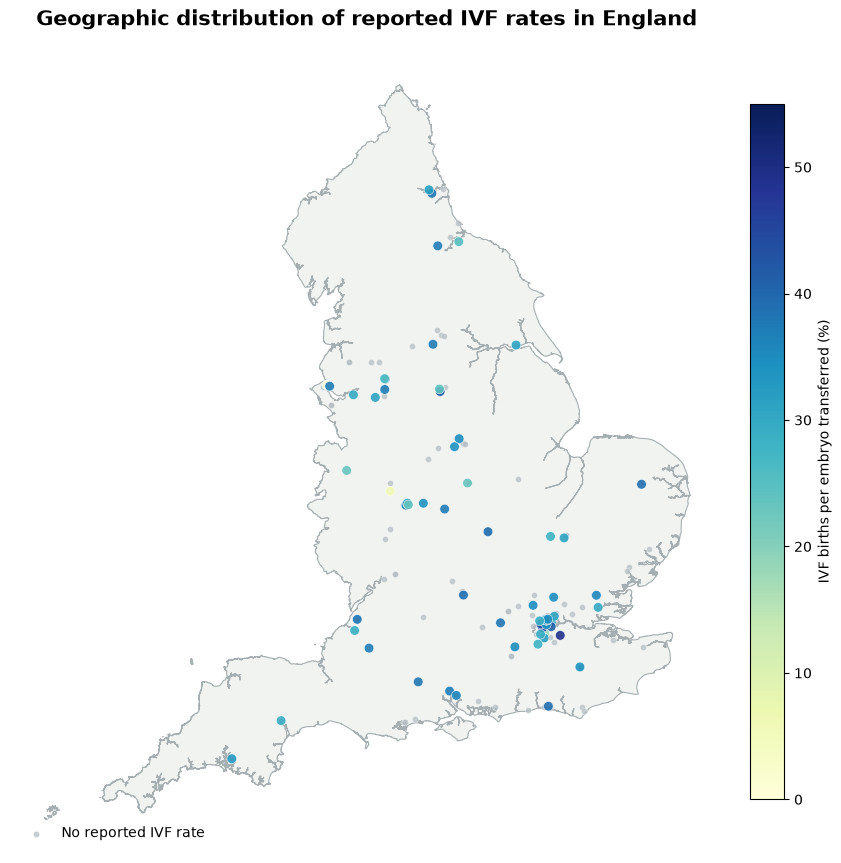

Clinics mapped: 183
With reported IVF rates: 77
Without reported IVF rates: 106


In [16]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from pathlib import Path
import requests
import geopandas as gpd

boundary_url = (
    "https://raw.githubusercontent.com/"
    "martinjc/UK-GeoJSON/master/json/administrative/"
    "gb/lad.json"
)

boundary_file = Path("data/uk_local_authorities.geojson")
boundary_file.parent.mkdir(parents=True, exist_ok=True)

# Download only if the file is not already saved
if not boundary_file.exists():
    response = requests.get(boundary_url, timeout=60)
    response.raise_for_status()
    boundary_file.write_bytes(response.content)

# Read the saved file
uk_boundaries = gpd.read_file(boundary_file)


uk_boundaries = gpd.read_file(boundary_url)

# Select local authorities in England
english_districts = uk_boundaries[
    uk_boundaries["LAD13CD"].str.startswith("E", na=False)
].copy()

# Combine local authorities into an England boundary
england_boundary = gpd.GeoDataFrame(
    geometry=[english_districts.geometry.union_all()],
    crs=uk_boundaries.crs
)

# IVF rates for patients under 38
ivf_map = outcomes[
    (outcomes["outcome"] == "IVF births per embryo transferred") &
    (outcomes["age_group"] == "Under 38")
][["clinic_name", "clinic_rate"]].copy()

# One observation per clinic in England
england = clinics[
    clinics["country"] == "England"
].drop(columns=["clinic_rate"], errors="ignore").copy()

england = england.merge(
    ivf_map,
    on="clinic_name",
    how="left",
    validate="one_to_one"
)

# Remove clinics without coordinates
england = england.dropna(subset=["latitude", "longitude"])

# Convert coordinates to geographic points
clinic_points = gpd.GeoDataFrame(
    england,
    geometry=gpd.points_from_xy(
        england["longitude"],
        england["latitude"]
    ),
    crs="EPSG:4326"
)

# Separate clinics with and without IVF rates
available = clinic_points[
    clinic_points["clinic_rate"].notna()
].copy()

missing = clinic_points[
    clinic_points["clinic_rate"].isna()
].copy()

# Use British National Grid for accurate map proportions
england_boundary = england_boundary.to_crs("EPSG:27700")
available = available.to_crs("EPSG:27700")
missing = missing.to_crs("EPSG:27700")

fig, ax = plt.subplots(figsize=(9, 11))

# England outline
england_boundary.plot(
    ax=ax,
    facecolor="#F1F3F1",
    edgecolor="#A5AFB1",
    linewidth=0.8,
    zorder=1
)

# Clinics without reported IVF rates
missing.plot(
    ax=ax,
    color="#B5BEC3",
    markersize=20,
    alpha=0.75,
    edgecolor="white",
    linewidth=0.3,
    label="No reported IVF rate",
    zorder=2
)

# Clinics with reported IVF rates
available.plot(
    ax=ax,
    column="clinic_rate",
    cmap="YlGnBu",
    vmin=0,
    vmax=55,
    markersize=48,
    alpha=0.9,
    edgecolor="white",
    linewidth=0.4,
    zorder=3
)

# Color scale
norm = Normalize(vmin=0, vmax=55)
sm = ScalarMappable(norm=norm, cmap="YlGnBu")
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    shrink=0.65,
    pad=0.03
)

cbar.set_label(
    "IVF births per embryo transferred (%)",
    fontsize=10
)

# Legend
ax.legend(
    loc="lower left",
    frameon=False,
    fontsize=10
)

ax.set_title(
    "Geographic distribution of reported IVF rates in England",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_aspect("equal")
ax.set_axis_off()

# Set limits based on England's boundary
xmin, ymin, xmax, ymax = england_boundary.total_bounds

ax.set_xlim(xmin - 30000, xmax + 30000)
ax.set_ylim(ymin - 30000, ymax + 30000)

plt.tight_layout()
plt.show()

print(f"Clinics mapped: {len(clinic_points)}")
print(f"With reported IVF rates: {len(available)}")
print(f"Without reported IVF rates: {len(missing)}")


Figure 5 shows the geographic distribution of fertility clinics in England and their reported IVF rates for patients under 38. Clinics are particularly concentrated around London and the southeast, although they are also distributed across other parts of England. There does not seem to be a clear geographic pattern in reported IVF rates, as clinics with higher and lower rates can be found in different areas. 

## 7. Discussion

In this project, I examined differences in reported fertility treatment outcomes across clinics in the UK. The clearest finding is that treatment outcomes differ considerably by age. Across all three treatments, clinics report higher average rates for patients under 38 than for patients aged 38 and over. I also found variation between clinics, particularly for IUI and donor insemination, while IVF rates were generally more concentrated.

When comparing clinic rates with national figures, I found that clinics were fairly evenly divided between those reporting rates above and below the national averages. The map also showed that fertility clinics are concentrated around London and the southeast of England, but I did not observe a clear geographic pattern in reported IVF rates.

There are some important limitations to this analysis. First, not all clinics have available outcome statistics, so the results are based on a subset of clinics. Second, I do not have information about the number of treatments performed at each clinic or the characteristics of their patients. This makes it difficult to determine whether differences in reported rates reflect differences in clinic performance or the patients they treat. Finally, the statistics come from different reporting periods, which may also affect comparisons.

Overall, this project helped me explore the differences in reported fertility treatment outcomes across clinics, while also showing some of the challenges of working with publicly available healthcare data.